In [1]:
import pandas as pd
import numpy as np

DATA_PATH = "../data/raw/cicids_ddos.csv"

df = pd.read_csv(DATA_PATH)

# Clean column names
df.columns = df.columns.str.strip()

print("Original shape:", df.shape)

Original shape: (225745, 79)


In [2]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)

df.dropna(inplace=True)

print("Shape after cleaning:", df.shape)

Shape after cleaning: (225711, 79)


In [3]:
columns_to_remove = [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp"
]

columns_to_remove = [
    column
    for column in columns_to_remove
    if column in df.columns
]

df.drop(columns=columns_to_remove, inplace=True)

print("Removed:", columns_to_remove)

Removed: []


In [4]:
df["Label"] = df["Label"].map({
    "BENIGN": 0,
    "DDoS": 1
})

print(df["Label"].value_counts())

Label
1    128025
0     97686
Name: count, dtype: int64


In [5]:
if df["Label"].isnull().sum() > 0:
    raise ValueError("Unexpected labels found in dataset.")

In [6]:
X = df.drop(columns=["Label"])
y = df["Label"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (225711, 78)
Target: (225711,)


In [7]:
non_numeric = X.select_dtypes(exclude=np.number).columns

print("Non-numeric features:")
print(non_numeric.tolist())

Non-numeric features:
[]


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (180568, 78)
Testing: (45143, 78)


In [9]:
stratify=y

In [10]:
from sklearn.ensemble import RandomForestClassifier
from time import perf_counter

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start = perf_counter()

rf_model.fit(X_train, y_train)

rf_training_time = perf_counter() - start

print(
    f"Random Forest training time: "
    f"{rf_training_time:.2f} seconds"
)

Random Forest training time: 4.06 seconds


In [11]:
rf_pred = rf_model.predict(X_test)

rf_probability = rf_model.predict_proba(X_test)[:, 1]

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_metrics = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_probability),
    "Training Time": rf_training_time
}

rf_metrics

{'Model': 'Random Forest',
 'Accuracy': 0.9998892408568327,
 'Precision': 0.9999218872051242,
 'Recall': 0.9998828353837141,
 'F1': 0.9999023609131208,
 'ROC-AUC': 0.999999696164369,
 'Training Time': 4.0570545840018895}

In [13]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [14]:
start = perf_counter()

xgb_model.fit(
    X_train,
    y_train
)

xgb_training_time = perf_counter() - start

print(
    f"XGBoost training time: "
    f"{xgb_training_time:.2f} seconds"
)

XGBoost training time: 1.49 seconds


In [15]:
xgb_pred = xgb_model.predict(X_test)

xgb_probability = xgb_model.predict_proba(X_test)[:, 1]

In [16]:
xgb_metrics = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "F1": f1_score(y_test, xgb_pred),
    "ROC-AUC": roc_auc_score(y_test, xgb_probability),
    "Training Time": xgb_training_time
}

xgb_metrics

{'Model': 'XGBoost',
 'Accuracy': 0.9999556963427331,
 'Precision': 1.0,
 'Recall': 0.9999218902558095,
 'F1': 0.999960943602562,
 'ROC-AUC': 0.9999995422476349,
 'Training Time': 1.4873006670095492}

In [17]:
comparison = pd.DataFrame([
    rf_metrics,
    xgb_metrics
])

comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Training Time
0,Random Forest,0.999889,0.999922,0.999883,0.999902,1.0,4.057055
1,XGBoost,0.999956,1.000000,0.999922,0.999961,1.0,1.487301


In [18]:
metrics_to_show = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

comparison_plot = comparison.set_index("Model")[metrics_to_show]

comparison_plot

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,0.999889,0.999922,0.999883,0.999902,1.0
XGBoost,0.999956,1.000000,0.999922,0.999961,1.0


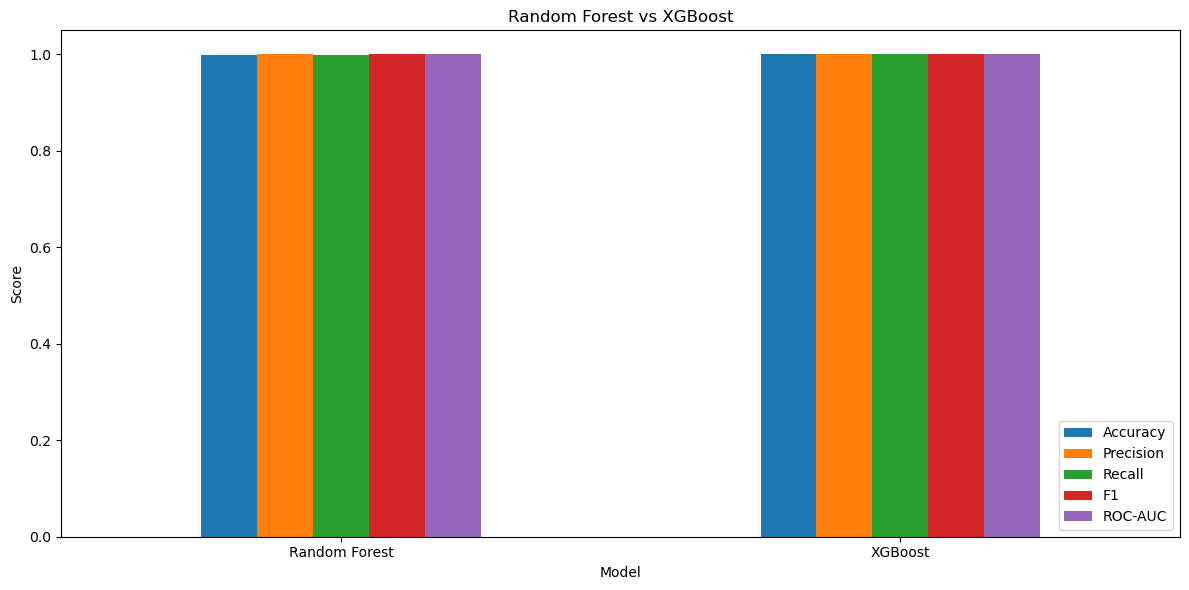

In [19]:
import matplotlib.pyplot as plt

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Random Forest vs XGBoost")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

In [20]:
from sklearn.metrics import classification_report

print("RANDOM FOREST")
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=["BENIGN", "DDoS"]
    )
)

RANDOM FOREST
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     19538
        DDoS       1.00      1.00      1.00     25605

    accuracy                           1.00     45143
   macro avg       1.00      1.00      1.00     45143
weighted avg       1.00      1.00      1.00     45143



In [21]:
print("XGBOOST")
print(
    classification_report(
        y_test,
        xgb_pred,
        target_names=["BENIGN", "DDoS"]
    )
)

XGBOOST
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     19538
        DDoS       1.00      1.00      1.00     25605

    accuracy                           1.00     45143
   macro avg       1.00      1.00      1.00     45143
weighted avg       1.00      1.00      1.00     45143



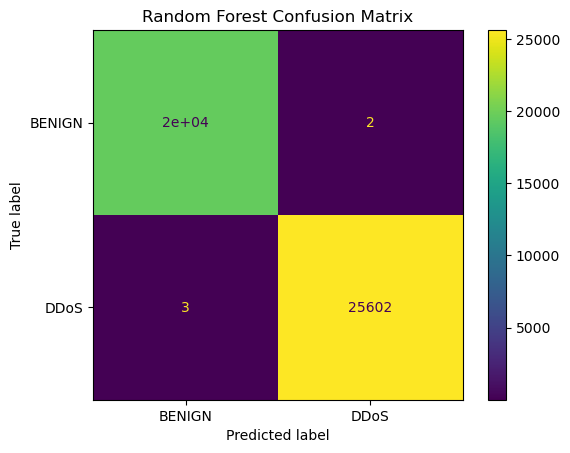

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["BENIGN", "DDoS"]
)

plt.title("Random Forest Confusion Matrix")
plt.show()

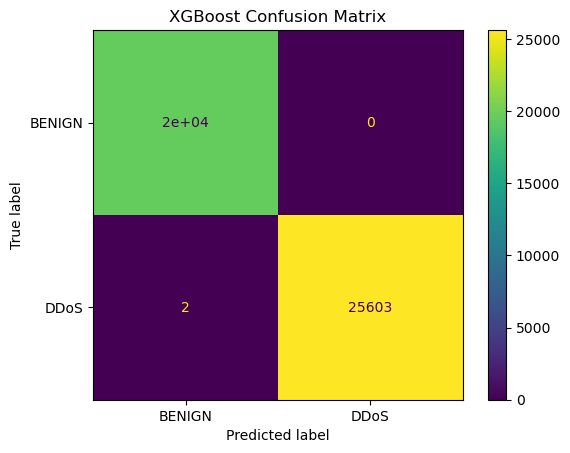

In [23]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred,
    display_labels=["BENIGN", "DDoS"]
)

plt.title("XGBoost Confusion Matrix")
plt.show()

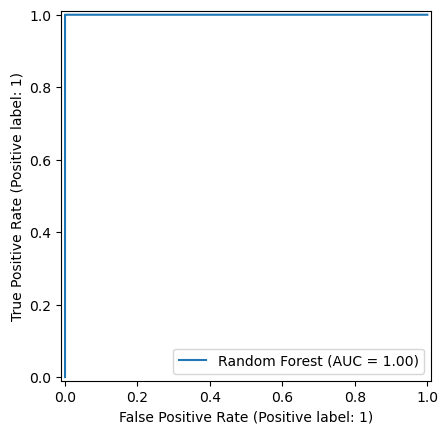

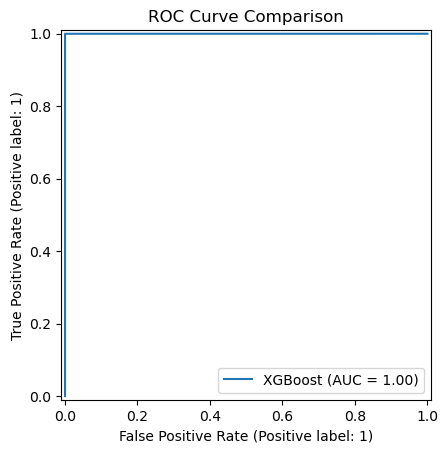

In [24]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    rf_probability,
    name="Random Forest"
)

RocCurveDisplay.from_predictions(
    y_test,
    xgb_probability,
    name="XGBoost"
)

plt.title("ROC Curve Comparison")

plt.show()

In [25]:
xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

xgb_importance.head(20)

,Feature,Importance
6,Fwd Packet Length Max,0.450966
4,Total Length of Fwd Packets,0.191499
53,Avg Fwd Segment Size,0.120906
63,Subflow Fwd Bytes,0.110781
8,Fwd Packet Length Mean,0.063408
68,act_data_pkt_fwd,0.043360
12,Bwd Packet Length Mean,0.003846
71,Active Std,0.002723
54,Avg Bwd Segment Size,0.000993
0,Destination Port,0.000667


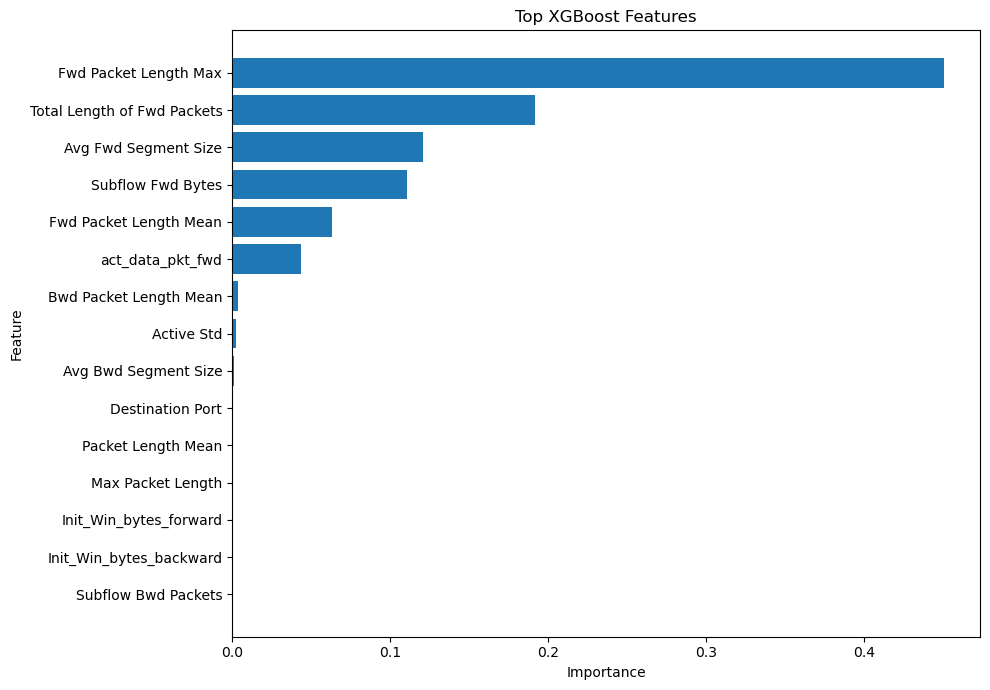

In [26]:
top_features = xgb_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top XGBoost Features")

plt.tight_layout()
plt.show()

In [27]:
import joblib

joblib.dump(
    xgb_model,
    "../models/xgboost_ids.pkl"
)

print("XGBoost model saved.")

XGBoost model saved.


In [28]:
if xgb_metrics["Recall"] > rf_metrics["Recall"]:
    best_model = xgb_model
    best_model_name = "XGBoost"

else:
    best_model = rf_model
    best_model_name = "Random Forest"

print("Selected model:", best_model_name)

Selected model: XGBoost


In [29]:
joblib.dump(
    best_model,
    "../models/best_ids_model.pkl"
)

print("Best IDS model saved.")

Best IDS model saved.
